# Task 2.2: Evaluating the best individual models

Every individual model tuned in Task 1.2, at its best configuration, plus the two naive baselines (Random
and Popularity), evaluated with our own metrics ([metrics.py](metrics.py), verified in
[task_2_1.ipynb](task_2_1.ipynb)).

**Protocol** (same as Task 1)

* MovieLens 100K, RecBole's random 80/10/10 split per user, seed 2020 (`load_split` in [recbole_utils.py](recbole_utils.py)).
* Full ranking: every item the user has not interacted with in train (+ valid, for test) is a candidate.
* Hyperparameters were chosen on **validation MRR@10** (Task 1.2). Everything reported below is on the
  **test** split, which played no part in any choice.
* Main cut-off K = 10. The per-user values of every metric are saved, so models can be compared with
  paired significance tests.

Run top to bottom. Results are cached in `results/task_2_2/`; set `RERUN = True` to retrain everything
(a few minutes on CPU, mostly SLIMElastic and FISM).

## 1. Setup

In [1]:
import time

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import wilcoxon

from metrics import K, evaluate_scores
from recbole_utils import ROOT, SEED, build_model, full_sort_fn, load_split, score_matrix, top_k

RESULTS_DIR = ROOT / "group_18" / "results" / "task_2_2"
PER_USER_DIR = RESULTS_DIR / "per_user"
RECS_DIR = RESULTS_DIR / "recommendations"
for d in (PER_USER_DIR, RECS_DIR):
    d.mkdir(parents=True, exist_ok=True)
SUMMARY_FILE = RESULTS_DIR / "summary.csv"

RERUN = False  # True retrains and re-evaluates every model; otherwise finished models are skipped

## 2. Models and their best configurations

For the tuned models we take the best row of the Task 1.2 grid search (by validation MRR@10), with one
exception:

* **EASE** keeps `reg_weight = 250` from its YAML. That value is not in the tuning grid, and it
  scored higher on validation (MRR@10 0.4201, Task 1.1) than the grid's best (500, 0.4189).

BPR's `reg_weight` was in the grid, but BPR does not use it (all three values give identical scores),
so it is left out.

NeuMF, LightGCN and NGCF from Task 1.1 are not included: they were not tuned in Task 1.2, so
their YAML-default results would not be a fair comparison.

In [2]:
# name: (RecBole model, config folder, hyperparameters, where they come from)
MODELS = {
    "ItemKNN": ("ItemKNN", "ItemKNN", {"k": 100, "shrink": 100}, "1.2 tuned (ItemCF)"),
    "UserKNN": ("ItemKNN", "UserKNN", {"k": 50, "shrink": 0}, "1.2 tuned (UserCF)"),
    "BPR": ("BPR", "BPR", {"embedding_size": 32, "learning_rate": 0.01}, "1.2 tuned"),
    "FISM": ("FISM", "FISM", {"embedding_size": 64, "learning_rate": 0.005, "alpha": 0.5,
                              "reg_weights": [1e-4, 1e-4]}, "1.2 tuned"),
    "SLIMElastic": ("SLIMElastic", "SLIMElastic", {"alpha": 0.1, "l1_ratio": 0.1}, "1.2 tuned (SLIM)"),
    "EASE": ("EASE", "EASE", {"reg_weight": 250.0}, "YAML (beats 1.2 grid on validation)"),
}
BASELINES = ["Random", "Popularity"]

# The tuned values must be the top row of the Task 1.2 results
TUNING_FILES = {"ItemKNN": "ItemCF", "UserKNN": "UserCF", "BPR": "BPR", "FISM": "FISM", "SLIMElastic": "SLIM"}
tuning_dir = next(d for d in (ROOT / "group_18" / "tuning_results", ROOT / "tuning_results")
                  if (d / "BPR_tuning.csv").exists())
for name, file in TUNING_FILES.items():
    best = pd.read_csv(tuning_dir / f"{file}_tuning.csv").sort_values("valid_score", ascending=False).iloc[0]
    for param, value in MODELS[name][2].items():
        assert str(best[param]) == str(value) or np.isclose(float(best[param]), value), (name, param, best[param], value)

pd.DataFrame([{"model": n, "hyperparameters": p, "source": s} for n, (_, _, p, s) in MODELS.items()]).set_index("model")

,hyperparameters,source
model,,
ItemKNN,"{'k': 100, 'shrink': 100}",1.2 tuned (ItemCF)
UserKNN,"{'k': 50, 'shrink': 0}",1.2 tuned (UserCF)
BPR,"{'embedding_size': 32, 'learning_rate': 0.01}",1.2 tuned
FISM,"{'embedding_size': 64, 'learning_rate': 0.005,...",1.2 tuned
SLIMElastic,"{'alpha': 0.1, 'l1_ratio': 0.1}",1.2 tuned (SLIM)
EASE,{'reg_weight': 250.0},YAML (beats 1.2 grid on validation)


## 3. Naive baselines

* **Random**: uniform random scores (fixed seed).
* **Popularity**: an item's number of training interactions, the same for every user.

This is *not* RecBole's `Pop` from Task 1.1, which scores lower (test MRR@10 0.195 vs. about 0.27
here). `Pop` counts items in `calculate_loss` with `item_cnt[item] = item_cnt[item] + 1`.
(1) It is a pointwise model, so with the default `train_neg_sample_args` each training batch also
contains uniformly sampled negatives, and those get counted too. (2) Fancy-index assignment with
repeated indices adds 1 per *batch*, not per interaction. Its scores are therefore a noisy count of
"batches containing the item", not real popularity.

The split is built once here as the reference. Every RecBole model rebuilds it from its own YAML, so
Section 4 checks that each model saw exactly the same test interactions.

In [3]:
_, ref_dataset, ref_train, ref_valid, ref_test = load_split("Pop")
N_USERS, N_ITEMS, UID = ref_dataset.user_num, ref_dataset.item_num, ref_dataset.uid_field

popularity = np.bincount(ref_train.dataset.inter_feat[ref_dataset.iid_field].numpy(), minlength=N_ITEMS).astype(np.float32)
_rng = np.random.default_rng(SEED)

BASELINE_SCORES = {
    "Popularity": lambda inter: torch.from_numpy(np.tile(popularity, (len(inter), 1))),
    "Random": lambda inter: torch.from_numpy(_rng.random((len(inter), N_ITEMS), dtype=np.float32)),
}

# items in the 10% most popular (by training interactions), used in Section 6
head_items = set(np.argsort(-popularity, kind="stable")[: int(0.1 * (N_ITEMS - 1))].tolist())
print(f"{N_USERS - 1} users, {N_ITEMS - 1} items, {len(ref_train.dataset)} training interactions")

943 users, 1682 items, 80808 training interactions


## 4. Run and evaluate

For each model: build (and train) it, score validation and test, compute all metrics, and save the
per-user test metrics and the top-10 lists (external ids) for later tasks. The popularity diagnostics
used in Section 6 are computed here as well:

* `pop_overlap@10`: share of a user's top 10 that is also in the Popularity baseline's top 10 for that user;
* `head_share@10`: share of recommended items that are among the 10% most popular items.

In [4]:
test_users = np.array(sorted({int(u) for u in ref_test.dataset.inter_feat[UID].numpy()}))
pop_scores, ref_test_items = score_matrix(BASELINE_SCORES["Popularity"], ref_test, N_USERS, N_ITEMS, UID)
pop_top = top_k(pop_scores, test_users, K)


def run(name):
    if name in BASELINE_SCORES:
        score_fn, dataset, valid, test = BASELINE_SCORES[name], ref_dataset, ref_valid, ref_test
    else:
        rb_model, config_name, params, _ = MODELS[name]
        model, _, dataset, _, valid, test = build_model(rb_model, config_name, **params)
        score_fn = full_sort_fn(model, dataset)

    valid_scores, valid_items = score_matrix(score_fn, valid, N_USERS, N_ITEMS, UID)
    test_scores, test_items = score_matrix(score_fn, test, N_USERS, N_ITEMS, UID)
    assert test_items == ref_test_items, f"{name}: different test split"

    valid_res = evaluate_scores(valid_scores, valid_items, ks=(K,))
    test_res = evaluate_scores(test_scores, test_items, ks=(K,))

    top = top_k(test_scores, test_users, K)
    overlap = np.array([len(set(a) & set(b)) / K for a, b in zip(top, pop_top)])
    head = np.isin(top, list(head_items)).mean(axis=1)

    per_user = test_res["per_user"].join(pd.DataFrame(
        {f"pop_overlap@{K}": overlap, f"head_share@{K}": head}, index=test_users))
    per_user.to_csv(PER_USER_DIR / f"{name}.csv")
    pd.DataFrame({
        "user_id": np.repeat(dataset.id2token(UID, test_users), K),
        "item_id": dataset.id2token(dataset.iid_field, top.ravel()),
        "rank": np.tile(np.arange(1, K + 1), len(test_users)),
    }).to_csv(RECS_DIR / f"{name}_top{K}.csv", index=False)

    return {"model": name, f"valid_mrr@{K}": valid_res["topk"].loc["mrr", f"@{K}"],
            **{f"{m}@{K}": v for m, v in test_res["topk"][f"@{K}"].items()},
            "auc": test_res["auc"], f"pop_overlap@{K}": overlap.mean(), f"head_share@{K}": head.mean()}


ALL = BASELINES + list(MODELS)
rows = [] if RERUN or not SUMMARY_FILE.exists() else pd.read_csv(SUMMARY_FILE).to_dict("records")
done = {row["model"] for row in rows}
for name in ALL:
    if name in done:
        continue
    start = time.time()
    rows.append(run(name))
    pd.DataFrame(rows).to_csv(SUMMARY_FILE, index=False)  # saved after every model
    print(f"done {name:12s} test NDCG@{K} = {rows[-1][f'ndcg@{K}']:.4f}  ({time.time() - start:.0f}s)")

summary = pd.read_csv(SUMMARY_FILE).set_index("model").loc[ALL]
per_user = {name: pd.read_csv(PER_USER_DIR / f"{name}.csv", index_col=0) for name in summary.index}

## 5. Results

### 5.1 Accuracy on the test split

Sorted by test NDCG@10. `valid MRR@10` is the selection metric from Task 1.2, shown to check that
the validation ranking carries over to test. Every metric is a per-user mean over the 943 test users.

In [5]:
ACC = ["precision", "recall", "f1", "hit", "ndcg", "mrr", "map"]
table = summary[[f"valid_mrr@{K}"] + [f"{m}@{K}" for m in ACC] + ["auc"]].sort_values(f"ndcg@{K}", ascending=False)
table.to_csv(RESULTS_DIR / "test_accuracy.csv")
display(table.round(4))

,valid_mrr@10,precision@10,recall@10,f1@10,hit@10,ndcg@10,mrr@10,map@10,auc
model,,,,,,,,,
EASE,0.4201,0.2206,0.2805,0.2012,0.8197,0.3295,0.5277,0.2065,0.9303
SLIMElastic,0.4165,0.2071,0.2646,0.1886,0.8038,0.3108,0.5113,0.1918,0.9200
UserKNN,0.4010,0.1909,0.2524,0.1760,0.7932,0.2877,0.4770,0.1722,0.9264
ItemKNN,0.3869,0.1830,0.2402,0.1683,0.7922,0.2819,0.4827,0.1692,0.9240
FISM,0.3429,0.1749,0.2072,0.1543,0.7349,0.2426,0.4104,0.1369,0.9307
BPR,0.3581,0.1629,0.2095,0.1489,0.7423,0.2354,0.3976,0.1314,0.9306
Popularity,0.2317,0.1029,0.1274,0.0915,0.5758,0.1416,0.2663,0.0697,0.8589
Random,0.0142,0.0094,0.0087,0.0074,0.0901,0.0107,0.0262,0.0035,0.5039


### 5.2 Improvement over the baselines, and significance

Relative change of test NDCG@10 and Recall@10 against Popularity. Significance uses a paired
Wilcoxon signed-rank test on per-user NDCG@10, against Popularity and against the best model on test
NDCG@10, with Holm correction over all comparisons in the table.

In [6]:
def holm(pvalues):
    p = np.asarray(pvalues, float)
    order = np.argsort(p)
    adjusted = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]).clip(max=1)
    out = np.empty_like(p)
    out[order] = adjusted
    return out


best = table.index[0]
metric = f"ndcg@{K}"
rows = []
for name in table.index:
    if name == "Popularity":
        continue
    row = {"model": name,
           f"ΔNDCG@{K} vs Pop": summary.loc[name, metric] / summary.loc["Popularity", metric] - 1,
           f"ΔRecall@{K} vs Pop": summary.loc[name, f"recall@{K}"] / summary.loc["Popularity", f"recall@{K}"] - 1,
           "p vs Pop": wilcoxon(per_user[name][metric], per_user["Popularity"][metric]).pvalue}
    row[f"p vs {best}"] = np.nan if name == best else wilcoxon(per_user[name][metric], per_user[best][metric]).pvalue
    rows.append(row)
sig = pd.DataFrame(rows).set_index("model")

pcols = ["p vs Pop", f"p vs {best}"]
flat = sig[pcols].to_numpy().ravel()
mask = ~np.isnan(flat)
flat[mask] = holm(flat[mask])
sig[pcols] = flat.reshape(sig[pcols].shape)
sig.to_csv(RESULTS_DIR / "significance.csv")

fmt = {c: "{:+.0%}" for c in sig.columns if c.startswith("Δ")} | {c: "{:.1e}" for c in pcols}
display(sig.style.format(fmt, na_rep="–"))

,ΔNDCG@10 vs Pop,ΔRecall@10 vs Pop,p vs Pop,p vs EASE
model,,,,
EASE,+133%,+120%,3.3e-95,–
SLIMElastic,+120%,+108%,4.4e-87,1.4e-06
UserKNN,+103%,+98%,1.6e-79,2.4e-20
ItemKNN,+99%,+89%,2.0e-71,4.0e-20
FISM,+71%,+63%,7.4e-42,6.2e-37
BPR,+66%,+64%,3.5e-37,1.3e-44
Random,-92%,-93%,1.2e-83,3.2e-126


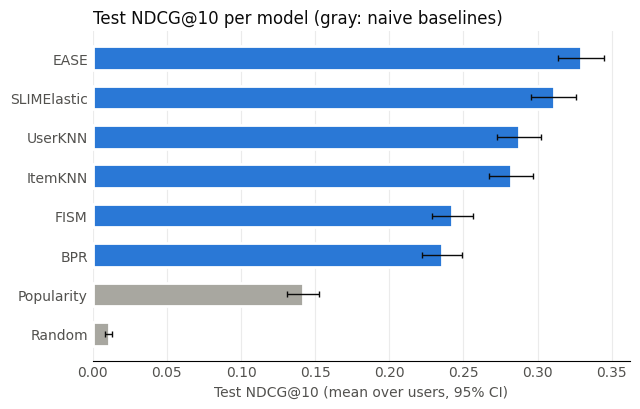

In [7]:
MODEL_COLOR, BASELINE_COLOR, INK, MUTED = "#2a78d6", "#a8a7a0", "#0b0b0b", "#52514e"

plot = table[[metric]].join(pd.Series({n: per_user[n][metric].sem() * 1.96 for n in table.index}, name="ci"))
plot = plot.iloc[::-1]
colors = [BASELINE_COLOR if n in BASELINES else MODEL_COLOR for n in plot.index]

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.barh(plot.index, plot[metric], height=0.6, color=colors, edgecolor="white", linewidth=2)
ax.errorbar(plot[metric], plot.index, xerr=plot["ci"], fmt="none", ecolor=INK, elinewidth=1, capsize=2)
ax.set_xlabel(f"Test NDCG@{K} (mean over users, 95% CI)", color=MUTED)
ax.set_title(f"Test NDCG@{K} per model (gray: naive baselines)", loc="left", color=INK)
ax.grid(axis="x", color="0.92")
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(colors=MUTED, length=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / f"test_ndcg{K}.png", dpi=200)
plt.show()

## 6. Personalisation beyond popularity

On ml-100k, Popularity is a strong baseline, because a few films account for a large share of all
ratings. The question for each model is how much of its accuracy comes from re-ranking the popular head,
and how much from finding items the popularity list would never show. The table and plot set accuracy
against two diagnostics computed on each model's test top 10:

* **overlap with Popularity**: share of the list also in the Popularity list for that user;
* **head share**: share of the list from the 10% most popular items.

,ndcg@10,pop_overlap@10,head_share@10
model,,,
EASE,0.330,0.271,0.878
SLIMElastic,0.311,0.295,0.908
UserKNN,0.288,0.312,0.935
ItemKNN,0.282,0.295,0.954
FISM,0.243,0.178,0.785
BPR,0.235,0.189,0.660
Popularity,0.142,1.000,1.000
Random,0.011,0.007,0.086


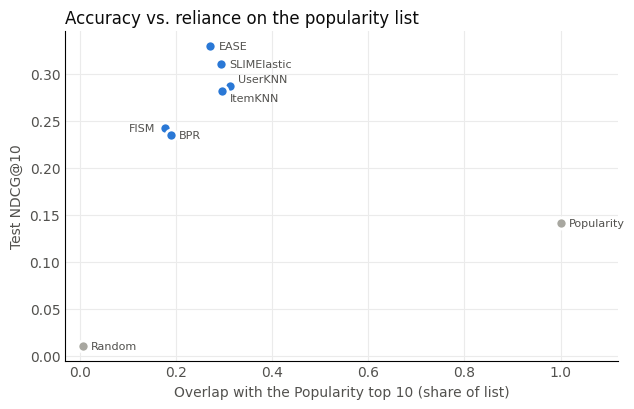

In [8]:
diag = summary[[metric, f"pop_overlap@{K}", f"head_share@{K}"]].sort_values(metric, ascending=False)
display(diag.round(3))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
models = diag.drop(index=BASELINES)
ax.scatter(models[f"pop_overlap@{K}"], models[metric], s=64, color=MODEL_COLOR, edgecolor="white", linewidth=2, zorder=3)
base = diag.loc[BASELINES]
ax.scatter(base[f"pop_overlap@{K}"], base[metric], s=64, color=BASELINE_COLOR, edgecolor="white", linewidth=2, zorder=3)
LABEL_OFFSETS = {"UserKNN": (6, 5, "left"), "ItemKNN": (6, -5, "left"), "FISM": (-7, 0, "right")}  # avoid collisions
for name, r in diag.iterrows():
    dx, dy, ha = LABEL_OFFSETS.get(name, (6, 0, "left"))
    ax.annotate(name, (r[f"pop_overlap@{K}"], r[metric]), xytext=(dx, dy), textcoords="offset points",
                ha=ha, va="center", fontsize=8, color=MUTED)
ax.set_xlabel(f"Overlap with the Popularity top {K} (share of list)", color=MUTED)
ax.set_ylabel(f"Test NDCG@{K}", color=MUTED)
ax.set_title("Accuracy vs. reliance on the popularity list", loc="left", color=INK)
ax.set_xlim(-0.03, 1.12)
ax.grid(color="0.92")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED, length=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / f"ndcg_vs_pop_overlap.png", dpi=200)
plt.show()

## 7. Observations

Numbers are on the test split, with K = 10. "Significant" means p < 0.001 in a Holm-corrected paired
Wilcoxon test on per-user NDCG@10.

* **Every model beats both baselines significantly.** Popularity itself is strong: NDCG@10 0.142, and
  58% of users get at least one hit, against 9% for Random. This is because ml-100k ratings are
  concentrated on a small head of well-known films.
* **The item-item linear models are best.** EASE (+133% NDCG@10 over Popularity) and SLIMElastic
  (+120%) learn an item-to-item weight matrix directly from co-occurrence. On a small catalogue with
  dense rows (1,682 items, about 6% density) that is enough data to estimate it well. EASE is
  significantly better than every other model, SLIM included. Its dense L2-regularised closed form
  keeps weak co-occurrence signals that SLIM's sparse elastic-net solution sets to zero.
* **The neighbourhood models personalise inside the head.** 93–95% of the items ItemKNN and UserKNN
  recommend come from the 10% most popular items. Yet only about 30% of their list is the Popularity
  list, so their gain comes from choosing *which* popular films fit each user.
* **The latent-factor models (BPR, FISM) reach further into the tail** (head share 0.66–0.79)
  and rank the whole catalogue as well as EASE (AUC 0.931 vs. 0.930). They are less sharp at the
  very top of the list. AUC and NDCG@10 disagree because AUC is dominated by the ranking of the many
  tail items, while NDCG@10 only looks at the first 10.
* **The validation ranking carries over to test.** The same four models lead on validation MRR@10 and
  on test NDCG@10, so the Task 1.2 choices did not overfit the validation split.